In [1]:
import pandas as pd

df = pd.read_parquet('C:/Users/NT751/Desktop/천영진/리스테리아ML/data/listeria_body.parquet')

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

df.head()

,lims_data_key,hazard_label,judge_result,src_route,data_source,expr_iem_nm,result_value,result_value_num,judge_stdr,judge_stdr_num,inspct_instt_code,prdlst_code,train_prdlst_code,train_prdlst_nm,prduct_nm,mnfctur_cmpny_nm,mnfctur_de,date_basis,addr,addr_source,legal_dong_code,lat,lon
0,O000001_160100103_5_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,0,0.0,<NA>,NaN,O000001,Z3800100000000,Z3800000000000,기타기준규격외,"화이트초콜릿 65℃, 30min",(주)쵸코하우스,2016-03-11,의뢰일,"경기도 성남시 중원구 둔촌대로 560(상대원동, 벽산테크노피아911,912,906,803호)",제조사소재지,4113310500,37.433239,127.164383
1,O000001_160100300_4_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000001,Z3800100000000,Z3800000000000,기타기준규격외,열무(세척전),(주)해마루,2016-03-22,의뢰일,"경기도 평택시 안중읍 성해2길 63-66 (학현리, 1, 2층)",제조사소재지,4122025300,36.986122,126.931168
2,O000033_170101151_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000033,Z2700400000000,Z2700000000000,"정액,수정란,종란","볶음-해물,야채(21일째)",<NA>,2017-02-22,제조일,전라북도 고창군 부안면 복분자로 434-36,업소주소,5279043000,35.514168,126.674095
3,O000027_170101235_2_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000027,Z3800100000000,Z3800000000000,기타기준규격외,크런치킹샌드(외포장),<NA>,2017-01-20,제조일,광주광역시 북구 하서로 222(양산동),업소주소,2917012800,35.209167,126.879715
4,1471142_170100097_1_1092137,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,1471142,B01010100F1000,B0100000000000,축산물,생고기2(삼정),<NA>,2017-03-07,제조일,전라북도 정읍시 정신로 22-12 (하북동),제조사소재지,5218012100,35.595753,126.869698


# 총 676537 rows × 23 columns

In [3]:
df['hazard_label'].value_counts()

hazard_label
리스테리아    676537
Name: count, dtype: int64

# 전부 리스테리아

# 칼럼명 한국어로 파악해야겠음

In [4]:
import pandas as pd

# 1. 엑셀 스키마 로드
schema_path = r'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'
schema = pd.read_excel(schema_path, sheet_name='ready_data', header=0)

# 필요한 컬럼 추출 및 결측치 제거
schema = schema[['컬럼', '설명']].dropna(subset=['컬럼'])

# 텍스트 양끝 공백 제거 (매칭률 향상)
schema['컬럼'] = schema['컬럼'].astype(str).str.strip()
schema['설명'] = schema['설명'].astype(str).str.strip()

# 엑셀 내 중복 컬럼명이 있을 경우 첫 번째 설명만 유지 (행 증폭 방지)
schema = schema.drop_duplicates(subset=['컬럼'], keep='first')

# 2. 데이터프레임 컬럼 추출 및 전처리
_df_columns = pd.DataFrame({'df_컬럼명': [str(col).strip() for col in df.columns]})

# 3. 매핑 수행
df_칼럼명 = _df_columns.merge(
    schema,
    left_on='df_컬럼명',
    right_on='컬럼',
    how='left'
).drop(columns=['컬럼']).rename(columns={'설명': '명세서_설명'})

# 4. 매칭 여부 플래그 생성
df_칼럼명['매칭여부'] = df_칼럼명['명세서_설명'].notna()

# 5. 결과 출력
display(df_칼럼명)

unmatched_cols = df_칼럼명.loc[~df_칼럼명['매칭여부'], 'df_컬럼명'].tolist()
print(f"총 컬럼 수: {len(df_칼럼명)}개 / 매칭 성공: {df_칼럼명['매칭여부'].sum()}개")
print('명세서 미매칭 컬럼:', unmatched_cols)

,df_컬럼명,명세서_설명,매칭여부
0,lims_data_key,PK. 소스별 조합 키,True
1,hazard_label,위해요소명 (10종),True
2,judge_result,목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출',True
3,src_route,NaN,False
4,data_source,NaN,False
5,expr_iem_nm,시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다,True
6,result_value,검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가,True
7,result_value_num,NaN,False
8,judge_stdr,NaN,False
9,judge_stdr_num,NaN,False


총 컬럼 수: 23개 / 매칭 성공: 18개
명세서 미매칭 컬럼: ['src_route', 'data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num']


# 타겟은 judge_result

# 제공받은 excel로 매핑했는데 nan은 뭐지? 값을 확인해야겠다
## mnfctur_de 칼럼의 fallback을 사용한다는게 뭐지?

In [5]:
# 명세서_설명이 NaN인 컬럼들의 df value_counts (결측 포함) → 하나의 데이터프레임으로 표시
미매칭_컬럼 = df_칼럼명.loc[df_칼럼명['명세서_설명'].isna(), 'df_컬럼명'].tolist()

_vc_list = []
for col in 미매칭_컬럼:
    vc = df[col].value_counts(dropna=False)
    _vc_list.append(pd.DataFrame({
        '컬럼': col,
        '값': vc.index.astype(object),
        '건수': vc.values,
        '비율(%)': (vc.values / len(df) * 100).round(2),
    }))

df_미매칭_value_counts = pd.concat(_vc_list, ignore_index=True)
print('대상 컬럼:', 미매칭_컬럼)
display(df_미매칭_value_counts)

대상 컬럼: ['src_route', 'data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num']


,컬럼,값,건수,비율(%)
0,src_route,domestic,628895,92.96
1,src_route,overseas,47642,7.04
2,data_source,식약처,676537,100.0
3,result_value_num,NaN,672760,99.44
4,result_value_num,0.0,3775,0.56
5,result_value_num,2.0,2,0.0
6,judge_stdr,<NA>,669264,98.92
7,judge_stdr,"n=5,c=0,m=0/25g",4692,0.69
8,judge_stdr,"n=5, c=0, m=0/25g",1817,0.27
9,judge_stdr,음성,635,0.09


# src_route제외 data_source,result_value_num,judge_stdr, judge_stdr_num 변수 전부 삭제해도 됨
# 그리고, 
받은 데이터의 
- 컬럼명
- 데이터타입
- 결측 수
- 결측 비율(%)
- 유니크 값 수 (결측 제외)
- 최빈값 5개
- 명세서_설명

을 데이터 프레임으로 정리

In [6]:
# df 전체 컬럼 요약: 컬럼명 / 데이터타입 / 결측 수 / 결측 비율 / 유니크 값 수 / 최빈값 5개
_n = len(df)
_rows = []
for col in df.columns:
    s = df[col]
    top5 = s.value_counts(dropna=True).head(5)
    _rows.append({
        '컬럼명': col,
        '데이터타입': str(s.dtype),
        '결측 수': int(s.isna().sum()),
        '결측 비율(%)': round(s.isna().mean() * 100, 2),
        '유니크 값 수': int(s.nunique(dropna=True)),
        '최빈값 5개': [f'{v} ({c:,})' for v, c in top5.items()],
    })

df_컬럼요약 = pd.DataFrame(_rows)
# 명세서 설명도 함께 붙이기
df_컬럼요약 = df_컬럼요약.merge(
    df_칼럼명[['df_컬럼명', '명세서_설명']],
    left_on='컬럼명', right_on='df_컬럼명', how='left'
).drop(columns='df_컬럼명')

print(f'총 {_n:,} rows × {df.shape[1]} columns')
display(df_컬럼요약)

총 676,537 rows × 23 columns


,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


# 타겟은 judge_result

# judge_result의 유니크 값별 수와 비율은?

In [7]:
# 타겟 judge_result 의 유니크 값별 건수와 비율 (결측 포함)
_vc = df['judge_result'].value_counts(dropna=False)
df_타겟분포 = pd.DataFrame({
    'judge_result': _vc.index.astype(object),
    '건수': _vc.values,
    '비율(%)': (_vc.values / len(df) * 100).round(3),
})
df_타겟분포.loc[len(df_타겟분포)] = ['합계', len(df), 100.0]

display(df_타겟분포)

,judge_result,건수,비율(%)
0,불검출,674568,99.709
1,검출,1969,0.291
2,합계,676537,100.000


# 양성 0.291% ;;

# 아래는 예측인자 도출을 위한 자료들. 참고하여 도출하자.

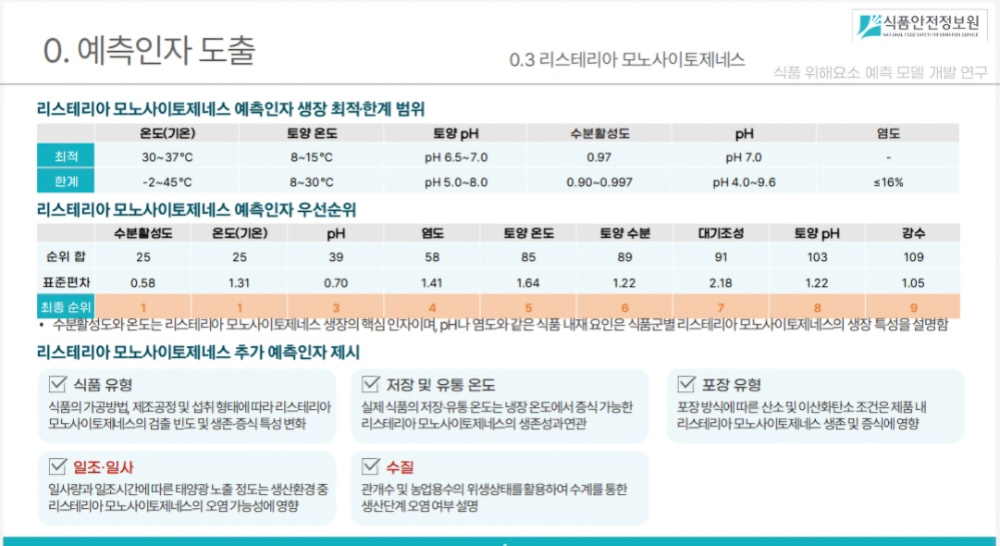

# 위 ppt에 따라
## 수집해야하는 기상변수 (중요도 순)
1. 수분활성도, 온도(기온). (리스테리아 생장의 핵심인자)
2. pH (식품 내재요인. 식품군별 리스테리아의 생장 특성을 설명함.)
3. 염도 (식품 내재요인. 식품군별 리스테리아의 생장 특성을 설명함.)
4. 토양온도
5. 토양 수분
6. 대기 조성
7. 토양 pH
8. 강수
9. 일조시간, 일사량
10. 수질
11. 저장 및 유통 온도(냉장 온도에서 증식가능한 리스테리아의 생존성과 연관)
## 수집해야하는 lims 변수
1. 식품 유형(식품의 가공방법, 제조공정, 섭취 형태에 떄하 검출 빈도 및 생존 증식 특성 변화.-> 진짜 그런가 분석을 통해 검증하자)
2. 포장 유형 (포장 방식에 따른 산소 및 이산화 탄소조건은 제품 내 리스테리아 생존 및 증식에 영향)

# prompt:
1. 수집해야하는 변수들이 'C:\Users\NT751\Desktop\천영진\리서치팀문서\위해요소별_중요인자_데이터출처.xlsx'의 '리스테리아 모노사이토제네스' 테이블에 빨간색으로 정리되어 있음。
2. 이미 수집되어 datagrip으로 다운 받을 수 있는 변수들이 'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'에 정리 되어있음。（노란색 배경은 필수 수집 변수）
3. 너의 목표는 'C:\Users\NT751\Desktop\천영진\리서치팀문서\위해요소별_중요인자_데이터출처.xlsx'의 '리스테리아 모노사이토제네스' 테이블에 빨간색으로 정리되어 있는 모든 변수를 'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'에서 찾아서 테이블명,칼럼명,설명으로 알려주기. 난 그걸받아서 DATAGRIP에서 다 수집하고, 수집 못한 변수를 따로 기상청 같은데서 수집할거야.
4. 'C:\Users\NT751\Desktop\천영진\리서치팀문서\위해요소별_중요인자_데이터출처.xlsx'의 '리스테리아 모노사이토제네스' 테이블에 빨간색으로 정의되어있는 변수명과 'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'의 '설명' 칼럼이 정확하게 맞지는 않을 수 있음. 그러나 애매한 것 까지 전부 포함하여 나한테 알려줘 (예를들어 'C:\Users\NT751\Desktop\천영진\리서치팀문서\위해요소별_중요인자_데이터출처.xlsx'의 '리스테리아 모노사이토제네스' 테이블에 빨간색으로 정의되어있는 변수명 '유효인산농도'. 그러나 'C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx'에는 '유효인산'으로 되어있을 수 있음. 이런경우 전부 포함에서 정리해서 알려주고 대신, 이런 불일치가 있었다 라는 식으로 알려줘.)
5. 추가적으로 아래에 포함되는 변수들도 추가.
{
## 수집해야하는 기상변수 (중요도 순)
1. 수분활성도, 온도(기온). (리스테리아 생장의 핵심인자)
2. pH (식품 내재요인. 식품군별 리스테리아의 생장 특성을 설명함.)
3. 염도 (식품 내재요인. 식품군별 리스테리아의 생장 특성을 설명함.)
4. 토양온도
5. 토양 수분
6. 대기 조성
7. 토양 pH
8. 강수
9. 일조시간, 일사량
10. 수질
11. 저장 및 유통 온도(냉장 온도에서 증식가능한 리스테리아의 생존성과 연관)
## 수집해야하는 lims 변수
1. 식품 유형(식품의 가공방법, 제조공정, 섭취 형태에 떄하 검출 빈도 및 생존 증식 특성 변화.-> 진짜 그런가 분석을 통해 검증하자)
2. 포장 유형 (포장 방식에 따른 산소 및 이산화 탄소조건은 제품 내 리스테리아 생존 및 증식에 영향)}
6. 추가적으로 리스테리아 불/검출 예측을 위해 더 발굴해야 할 변수들을 생각해서 알려줘. 니 생각의 근거, 수집방안은 모두{C:\Users\NT751\Desktop\천영진\리서치팀문서\위해요소별_중요인자_데이터출처.xlsx,C:\Users\NT751\Desktop\천영진\테이블명세서(모델팀)\테이블정의서.xlsx}에서 찾을 수 있어야함.

In [8]:
df

,lims_data_key,hazard_label,judge_result,src_route,data_source,expr_iem_nm,result_value,result_value_num,judge_stdr,judge_stdr_num,inspct_instt_code,prdlst_code,train_prdlst_code,train_prdlst_nm,prduct_nm,mnfctur_cmpny_nm,mnfctur_de,date_basis,addr,addr_source,legal_dong_code,lat,lon
0,O000001_160100103_5_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,0,0.0,<NA>,NaN,O000001,Z3800100000000,Z3800000000000,기타기준규격외,"화이트초콜릿 65℃, 30min",(주)쵸코하우스,2016-03-11,의뢰일,"경기도 성남시 중원구 둔촌대로 560(상대원동, 벽산테크노피아911,912,906,803호)",제조사소재지,4113310500,37.433239,127.164383
1,O000001_160100300_4_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000001,Z3800100000000,Z3800000000000,기타기준규격외,열무(세척전),(주)해마루,2016-03-22,의뢰일,"경기도 평택시 안중읍 성해2길 63-66 (학현리, 1, 2층)",제조사소재지,4122025300,36.986122,126.931168
2,O000033_170101151_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000033,Z2700400000000,Z2700000000000,"정액,수정란,종란","볶음-해물,야채(21일째)",<NA>,2017-02-22,제조일,전라북도 고창군 부안면 복분자로 434-36,업소주소,5279043000,35.514168,126.674095
3,O000027_170101235_2_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000027,Z3800100000000,Z3800000000000,기타기준규격외,크런치킹샌드(외포장),<NA>,2017-01-20,제조일,광주광역시 북구 하서로 222(양산동),업소주소,2917012800,35.209167,126.879715
4,1471142_170100097_1_1092137,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,1471142,B01010100F1000,B0100000000000,축산물,생고기2(삼정),<NA>,2017-03-07,제조일,전라북도 정읍시 정신로 22-12 (하북동),제조사소재지,5218012100,35.595753,126.869698
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
676532,1471124_170704332_1_11,리스테리아,불검출,overseas,식약처,리스테리아 모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,1471124,C0201110200000,C0318000000000,유가공품류,반경성치즈,<NA>,2017-07-19,선적일,5331 GREAT OCEAN ROAD ALLANSFORD VIC 3277,해외제조업소,NaN,-38.395367,142.627716
676533,O000024_160103149_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000024,C0121020000000,C0312000000000,조미식품,엄지 곤육수,<NA>,2016-06-08,의뢰일,전북특별자치도 김제시 봉황공단2길 107(오정동),인허가대장,5221011800,35.774906,126.917442
676534,O000024_160105715_1_4,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000024,C0123020000000,C0313000000000,절임류 또는 조림류,우리땅배추김치(한라),<NA>,2016-08-30,제조일,경상남도 거창군 가조면 석강3길 127,인허가대장,4888040000,35.710964,128.014709
676535,O000031_170700207_1_5,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000031,C0201180100000,C0318000000000,유가공품류,SRC딸기아이스크림,<NA>,2017-03-29,제조일,충청북도 음성군 삼성면 덕호로94번길 5,인허가대장,4377035000,37.018387,127.495041


In [9]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [10]:
# date_basis 값별 건수 및 비율
_vc = df['date_basis'].value_counts(dropna=False)

df_date_basis = pd.DataFrame({
    'date_basis': _vc.index.astype(object),
    '건수': _vc.values,
    '비율(%)': (_vc.values / len(df) * 100).round(2),
})

df_date_basis.loc[len(df_date_basis)] = ['합계', len(df), 100.0]

display(df_date_basis)

,date_basis,건수,비율(%)
0,의뢰일,333425,49.28
1,제조일,296040,43.76
2,선적일,47072,6.96
3,합계,676537,100.00


In [11]:
import pandas as pd

# date_basis == '선적일' 인 행의 judge_result, addr_source, addr 값 비율

ship = df[df['date_basis'].eq('선적일')].copy()
n = len(ship)

print(f"date_basis='선적일' 행 수: {n:,}")

# 1) judge_result 비율
vc_judge = ship['judge_result'].value_counts(dropna=False)
df_judge = pd.DataFrame({
    'judge_result': vc_judge.index.astype(object),
    '건수': vc_judge.values,
    '비율(%)': (vc_judge.values / n * 100).round(3),
})
df_judge.loc[len(df_judge)] = ['합계', n, 100.0]
display(df_judge)

# 2) addr_source 비율
vc_addr_source = ship['addr_source'].value_counts(dropna=False)
df_addr_source = pd.DataFrame({
    'addr_source': vc_addr_source.index.astype(object),
    '건수': vc_addr_source.values,
    '비율(%)': (vc_addr_source.values / n * 100).round(3),
})
df_addr_source.loc[len(df_addr_source)] = ['합계', n, 100.0]
display(df_addr_source)

# 3) addr 값 비율 (상위 20개만 보기)
vc_addr = ship['addr'].value_counts(dropna=False).head(20)
df_addr = pd.DataFrame({
    'addr': vc_addr.index.astype(object),
    '건수': vc_addr.values,
    '비율(%)': (vc_addr.values / n * 100).round(3),
})
df_addr['누적비율(%)'] = df_addr['비율(%)'].cumsum().round(3)
display(df_addr)

date_basis='선적일' 행 수: 47,072


,judge_result,건수,비율(%)
0,불검출,46947,99.734
1,검출,125,0.266
2,합계,47072,100.000


,addr_source,건수,비율(%)
0,해외제조업소,47072,100.0
1,업소주소,0,0.0
2,인허가대장,0,0.0
3,제조사소재지,0,0.0
4,합계,47072,100.0


,addr,건수,비율(%),누적비율(%)
0,155 RTE DE CAMBRAI BP59 62217 TILLOY LES MOFFLAINES,960,2.039,2.039
1,VIA BRENNERO 2 VARNA (BOLZANO),527,1.12,3.159
2,"99/88 MU 4, KANCHU, BUENG SAM PHAN, PHETCHABUN, 67160",482,1.024,4.183
3,"30-3 SHINISOGO-CHO, ISOGO-KU, YOKOHAMA-CITY KANAGAWA, JAPAN",477,1.013,5.196
4,VIA ISEO 52-ERBUSCO (BRESCIA),406,0.863,6.059
5,"N4056 VINE RD. APPLETON, WI54913",394,0.837,6.896
6,"YUEJIN EAST ROAD, HUANGCHUAN COUNTRY, HENAN PROVINCE, CHINA",346,0.735,7.631
7,"885 NORTH 600 WEST, LOGAN, UT 84321",296,0.629,8.26
8,"628-1 SHISHIHARA, SHIMIZU-KU, SHIZUOKA-CITY,SHIZUOKA-PREF, JAPAN",262,0.557,8.817
9,"VIA E. ELIA, 10 10020 LAURIANO (TORINO)",261,0.554,9.371


In [12]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [13]:
# train_prdlst_nm 칼럼의 모든 유니크 값들에 대한 judge_result 값 비율
# judge_result 값 범주를 명시적으로 맞추기
target_col = 'judge_result'
feature_col = 'train_prdlst_nm'

# 교차표 생성
ct = pd.crosstab(df[feature_col], df[target_col], dropna=False)

# 필요한 컬럼만 유지하고, 없는 경우 0으로 채움
for cls in ['검출', '불검출']:
    if cls not in ct.columns:
        ct[cls] = 0

ct = ct[['검출', '불검출']].copy()

# 총건수 / 비율 계산
ct['총건수'] = ct.sum(axis=1)
ct['검출비율(%)'] = (ct['검출'] / ct['총건수'] * 100).round(3)
ct['불검출비율(%)'] = (ct['불검출'] / ct['총건수'] * 100).round(3)

# 보기 편하게 리셋 인덱스
df_train_prdlst_judge_ratio = ct.reset_index().rename(columns={feature_col: feature_col})

# 정렬: 검출비율 높은 순
df_train_prdlst_judge_ratio = df_train_prdlst_judge_ratio.sort_values('검출비율(%)', ascending=False)

display(df_train_prdlst_judge_ratio)

judge_result,train_prdlst_nm,검출,불검출,총건수,검출비율(%),불검출비율(%)
20,버섯류,12,80,92,13.043,86.957
9,기타식물류,2,41,43,4.651,95.349
39,"정액,수정란,종란",640,28011,28651,2.234,97.766
46,축산물,28,1703,1731,1.618,98.382
25,수산가공식품류,29,4886,4915,0.590,99.410
26,수산물,46,8427,8473,0.543,99.457
2,견과 종실류,1,291,292,0.342,99.658
28,식육가공품 및 포장육,323,100722,101045,0.320,99.680
8,기타기준규격외,791,291022,291813,0.271,99.729
44,즉석식품류,45,35277,35322,0.127,99.873


In [14]:
positive_categories = ct[ct['검출'] > 0].index

print(f"검출 값이 0 초과인 train_prdlst_nm 수: {len(positive_categories)}")
display(pd.DataFrame({'train_prdlst_nm': positive_categories}))

검출 값이 0 초과인 train_prdlst_nm 수: 15


,train_prdlst_nm
0,견과 종실류
1,"과자류, 빵류 또는 떡류"
2,기타기준규격외
3,기타식물류
4,기타식품류
5,농산가공식품류
6,버섯류
7,수산가공식품류
8,수산물
9,식육가공품 및 포장육


In [15]:
positive_categories = ct[ct['검출'] > 0].index

print(f"검출 값이 0 초과인 train_prdlst_nm 수: {len(positive_categories)}")
print(f"train_prdlst_nm: {list(positive_categories)}")

검출 값이 0 초과인 train_prdlst_nm 수: 15
train_prdlst_nm: ['견과 종실류', '과자류, 빵류 또는 떡류', '기타기준규격외', '기타식물류', '기타식품류', '농산가공식품류', '버섯류', '수산가공식품류', '수산물', '식육가공품 및 포장육', '유가공품류', '음료류', '정액,수정란,종란', '즉석식품류', '축산물']


# 기타기준규격외 가 젤 많음

In [16]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

mask = (df['train_prdlst_nm'].eq('기타기준규격외')) & (df['judge_result'].eq('검출'))

unique_prduct_nm = (
    df.loc[mask, 'prduct_nm']
      .dropna()
      .astype(str)
      .drop_duplicates()
      .reset_index(drop=True)
)

print(f'기타기준규격외 & judge_result == 검출 조건의 prduct_nm 유니크 수: {len(unique_prduct_nm)}')
display(unique_prduct_nm.to_frame(name='prduct_nm'))

기타기준규격외 & judge_result == 검출 조건의 prduct_nm 유니크 수: 706


,prduct_nm
0,부드러운양념목살구이
1,이베리코 통목살 스테이크
2,가마로순살강정육 1차
3,얇은고명지단
4,완제품2
5,양념육(매콤달콤 갈비맛닭갈비)
6,원료육-입고후 1차
7,브라질산닭(원물)
8,칠게장 세척 전
9,미산성소독전


# 완제품2, 미산성 소독전 등.. 이건 뭐지. 내가 알아야하나? 돼지 3차? 
# 암튼 데이터 그렇게 좋진 않음 

In [17]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [18]:
import re
import pandas as pd

# 1) 조건: judge_result == '검출' 이고 prduct_nm 에 포함된 키워드
keywords = ['산', '미국', '브라질', '베트남', '캐나다', '노르웨이', '수입']
pattern = '|'.join(re.escape(k) for k in keywords)

mask = (
    df['judge_result'].eq('검출')
    & df['prduct_nm'].astype(str).str.contains(pattern, regex=True, case=False, na=False)
)

sub = df.loc[mask, ['prduct_nm', 'date_basis', 'addr', 'addr_source','mnfctur_cmpny_nm']].copy()

print(f"조건에 맞는 행 수: {len(sub):,}")
print(f"조건에 맞는 prduct_nm 유니크 수: {sub['prduct_nm'].dropna().astype(str).nunique():,}")

# 2) 각 컬럼의 유니크 값 정리
cols = ['prduct_nm', 'date_basis', 'addr', 'addr_source', 'mnfctur_cmpny_nm']
rows = []

for col in cols:
    uniq = sub[col].dropna().astype(str).drop_duplicates().sort_values().tolist()
    rows.append({
        '컬럼': col,
        '유니크값수': len(uniq),
        '유니크값들': uniq,
    })

df_unique_summary = pd.DataFrame(rows)
display(df_unique_summary)

# 필요하면 원본 filtered DataFrame도 함께 보여주기
display(sub)

조건에 맞는 행 수: 78
조건에 맞는 prduct_nm 유니크 수: 73


,컬럼,유니크값수,유니크값들
0,prduct_nm,73,"[100% 국산들깨가루(샘플), 20170713노르웨이연어(BL18061054770)1-1, 20170713노르웨이연어(BL18061054770)1-2, 20170713노르웨이연어(BL18061054770)2-1, 2차해동(축산1차), 가자미살(미국) 해양에프에스(1-3), 가자미살(미국,러시아) 남양씨푸드(1-14), 고등어(노르웨이), 고등어살(국산) 수협중앙회(1-4), 고사리(중국산), 곰곰국내산닭을사용한간장맛닭갈비(완제품), 국내산 돈후지 - 원료육, 국내산 막창, 국내산돼지앞다리불고기용, 국내산후지(원물), 국산 냉동 삼겹살(금천 대전), 낙지(베트남), 농산물(생강)(세척전)1차, 농협안심한우육회(국내산), 다리정육(국내산), 닭산적 냉장 후, 닭정육(브라질산), 대한민국 농수산 제주돼지왕구이 - 완제품, 돈삼겹(독일산), 돈육(우리흑돈 삼겹살/안동봉화축협 안동축산물공판장), 동태살(수입) 수협중앙회(1-3), 동태절(러시아산), 돼지고기(목전지)_수입산, 미산성소독전, 미산성소독후, 베트남 고기 짜조 (살균 전), 베트남 전통햄, 베트남전통햄, 브라질산닭(원물), 삼치살(국산)-수협중앙회(1-3), 생산 22.07.12 소독,헹굼 전, 섭산적 가열전, 성산포크 (공정별_발골), 소염통(포장육)-생산후1, 수산물 증숙전, 수산물 프라이 전, 수입육 등심 3차, 아귀살(국산) 태진수산(1-11), 아쉬순살(국산), 양념육(브라질산정육)-원료육(냉동보관전), 양념육(브라질산정육)-원료육(냉동보관중), 연어(노르웨이산), 연어(캐나다산), 연어필렛(노르웨이산), 완제품 냉장부채 생산후, 완제품 냉장부채 생산후(120시간 경과), 완제품 생산직후, 우육 원료육(우육 목심/호주산), 이산화10분세척, 이산화10분휘발, 이산화세척-8월6일, 이산화염소100ppm15분연어, 이산화염소수, 임연수살(미국), 임연수살(미국)-해양에프에스(1-17), 제주산후지(원물), 주꾸미(베트남), 쭈꾸미채(베트남), 차아염소산, 차아염소산나트륨, 차아염소산나트륨-세척, 청산별덕 훈제오리S_T2, 청산별덕 훈제오리S_T3, 축산물(미생물5번), 축산물FRY전(1차), 축산물FRY전(2차), 축산물FRY전(3차), 호주산 우둔 냉장 후 1차]"
1,date_basis,2,"[의뢰일, 제조일]"
2,addr,41,"[경기 광주시 오포읍 포은대로 640-8, 경기 화성시 안녕남로 24 (안녕동), 경기도 과천시 관문로 47 정부과천청사 4동 6,7층, 경기도 광주시 곤지암읍 경충대로 731, 1층, 2층, 경기도 광주시 곤지암읍 경충대로 731, 2층(친환경농산물유통센터), 경기도 광주시 오포읍 고산길 181, 경기도 김포시 하성면 애기봉로 761 가동 1,2,3층, 경기도 성남시 중원구 갈마치로 234 지층 비116호(상대원동, SK아파트형공장), 경기도 시흥시 도창동 413-2, 경기도 안산시 상록구 수암4길 17, 102호 (수암동), 경기도 안성시 원곡면 기업단지로 293-4, 경기도 용인시 기흥구 공세로 22 (고매동), 경기도 용인시 기흥구 덕영대로1967번길 35(하갈동), 경기도 용인시 처인구 모현면 파담로 36 (갈담리), 경기도 용인시 처인구 양지면 양지로23번길 6, 2동 1층, 경기도 이천시 신둔면 경충대로 3166 ,1층, 경기도 이천시 진상미로 2170-19 (고담동), 경기도 이천시 호법면 안평리 38-14, 경기도 화성시 서신면 바다뜰길 8-9 (매화리), 경기도 화성시 화산남로55번길 20 (송산동), 광주광역시 광산구 임방울대로358번길 28 , 1층, 서울시 서초구 마방로, 서울특별시 금천구 범안로21길 8, B201호, B3층 (독산동), 서울특별시 성동구 고산자로20길 10, (마장동), 서울특별시 성동구 성수이로22길 55, 신창인쇄빌딩 1,2,3,4층 (성수동2가), 인천 남동구 청능대로448번길 149-12(고잔동), 인천광역시 강화군 선원면 고식이길 208, 인천광역시 계양구 봉오대로 468 (효성동), 인천광역시 계양구 아나지로 420, 인천광역시 계양구 아나지로 420 (작전동), 인천광역시 남동구 앵고개로653번길 77, 인천광역시 남동구 청능대로448번길 149-12(H동, I동 1층 전부호 고잔동), 인천광역시 미추홀구 연남로 35(관교동), 인천광역시 서구 검단로93번길 9 (오류동), 인천광역시 중구 축항대로 50 1층 (항동7가, 외 1필지), 전라남도 나주시 동수농공단지길 62-215, 전라북도 정읍시 신태인읍 석지로 621-52, 제주특별자치도 제주시 오도1길 9, 1층 (이호이동), 충청북도 음성군 대소면 대금로105번길 70, 충청북도 음성군 맹동면 맹동산단1길 85, 충청북도 충주시 대소원면 메가폴리스로 42]"
3,addr_source,2,"[업소주소, 제조사소재지]"
4,mnfctur_cmpny_nm,5,"[(주)살롱드파파푸드그룹, (주)성림쓰리에이통상, (주)한성미트, 농업회사법인가은MPC(주), 주식회사 타라]"


,prduct_nm,date_basis,addr,addr_source,mnfctur_cmpny_nm
5664,브라질산닭(원물),의뢰일,경기도 화성시 서신면 바다뜰길 8-9 (매화리),업소주소,<NA>
8681,미산성소독전,의뢰일,"광주광역시 광산구 임방울대로358번길 28 , 1층",제조사소재지,(주)살롱드파파푸드그룹
13275,수산물 증숙전,의뢰일,인천광역시 서구 검단로93번길 9 (오류동),업소주소,<NA>
18385,임연수살(미국),의뢰일,경기 화성시 안녕남로 24 (안녕동),업소주소,<NA>
18810,낙지(베트남),의뢰일,경기도 용인시 기흥구 덕영대로1967번길 35(하갈동),업소주소,<NA>
23087,청산별덕 훈제오리S_T3,제조일,경기도 안성시 원곡면 기업단지로 293-4,업소주소,<NA>
27837,아귀살(국산) 태진수산(1-11),의뢰일,"경기도 광주시 곤지암읍 경충대로 731, 2층(친환경농산물유통센터)",업소주소,<NA>
45309,수입육 등심 3차,의뢰일,전라북도 정읍시 신태인읍 석지로 621-52,업소주소,<NA>
58623,"가자미살(미국,러시아) 남양씨푸드(1-14)",의뢰일,"경기도 광주시 곤지암읍 경충대로 731, 2층(친환경농산물유통센터)",업소주소,<NA>
68987,완제품 냉장부채 생산후,의뢰일,"서울특별시 금천구 범안로21길 8, B201호, B3층 (독산동)",업소주소,<NA>


In [19]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


# 제품명을 보면 해외 제품들인데 주소는 국내임.. 노이즈로 보임.

In [20]:
# 기존 셀에서 이미 정의된 df, train_prdlst_nm, judge_result 사용
mask = (
    df['train_prdlst_nm'].eq('기타기준규격외') &
    df['judge_result'].eq('검출')
)

# 대상 subset: prduct_nm 기준으로 원본 행 수 유지
s = df.loc[mask, 'prduct_nm'].dropna().astype(str)

# prduct_nm별 검출 건수
prod_counts = s.value_counts()

# 중복되는 prduct_nm만 추출
dup_products = prod_counts[prod_counts > 1]

# 중복으로 추가된 행 수 = (각 prduct_nm 건수 - 1)의 합계
extra_duplicate_rows = int((dup_products - 1).sum())

print(f"기타기준규격외 & judge_result == '검출' 조건의 전체 검출 행 수: {len(s):,}")
print(f"중복으로 등장하는 prduct_nm 수: {len(dup_products):,}")
print(f"중복으로 추가된 행 수(중복 그룹 내 초과 행 수): {extra_duplicate_rows:,}")

# 중복 product name + 확인용 DataFrame
df_dup_prduct_nm = pd.DataFrame({
    'prduct_nm': dup_products.index,
    '검출행수': dup_products.values,
    '중복추가행수': dup_products.values - 1
})

display(df_dup_prduct_nm.sort_values('검출행수', ascending=False))

기타기준규격외 & judge_result == '검출' 조건의 전체 검출 행 수: 791
중복으로 등장하는 prduct_nm 수: 51
중복으로 추가된 행 수(중복 그룹 내 초과 행 수): 85


,prduct_nm,검출행수,중복추가행수
0,광어회,10,9
1,연어회,9,8
2,연어필렛,6,5
3,포장육 완제품,5,4
4,팽이버섯,4,3
5,연어(캐나다산),4,3
6,홍새우회,4,3
7,가마로순살강정육 1차,3,2
8,완제품1,3,2
9,클린콜,3,2


# 회가 많네.. 가공안된 원물이긴한데.. 손질과정에서 오염됐을 수 도 있음

In [21]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

mask = (df['train_prdlst_nm'].eq('정액,수정란,종란')) & (df['judge_result'].eq('검출'))

unique_prduct_nm = (
    df.loc[mask, 'prduct_nm']
      .dropna()
      .astype(str)
      .drop_duplicates()
      .reset_index(drop=True)
)

print(f'정액,수정란,종란 & judge_result == 검출 조건의 prduct_nm 유니크 수: {len(unique_prduct_nm)}')
display(unique_prduct_nm.to_frame(name='prduct_nm'))

정액,수정란,종란 & judge_result == 검출 조건의 prduct_nm 유니크 수: 493


,prduct_nm
0,소독.헹굼공정 유효성평가(0초)
1,A-45초
2,팽이버섯-권지 포크 (표면)
3,ENOKI MUSHROOM GR07
4,ENOKI MUSHROOM 수확전-5
5,ENOKI MUSHROOM GR3-2
6,팽이버섯-1.7 균긁기 칼날 1
7,샐러드 소불고기 가열 전
8,컨베이어1
9,생육실 2-1


# 계란이 없는데? 팽이버섯 많음 이거 팽이버섯 류로 넣어야하는거 아님?

In [22]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [23]:
# train_prdlst_code가 결측인 전체 행 조회
missing_code_rows = df[df['train_prdlst_code'].isna()].copy()

print(f"train_prdlst_code 결측 행 수: {len(missing_code_rows):,}")
display(missing_code_rows)

train_prdlst_code 결측 행 수: 170


,lims_data_key,hazard_label,judge_result,src_route,data_source,expr_iem_nm,result_value,result_value_num,judge_stdr,judge_stdr_num,inspct_instt_code,prdlst_code,train_prdlst_code,train_prdlst_nm,prduct_nm,mnfctur_cmpny_nm,mnfctur_de,date_basis,addr,addr_source,legal_dong_code,lat,lon
176,O000039_170124218_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,돈까스-개,<NA>,2017-10-19,제조일,경상남도 김해시 김해대로 2078 (내동),업소주소,4825010800,35.235214,128.864655
238,O000039_170128930_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,이태원청춘핫윙봉(20입),<NA>,2017-12-13,제조일,"인천광역시 남동구 청능대로 596, 지하1층(논현동,푸르지오시티(홈플러스입점2호))",업소주소,2820011000,37.404209,126.716370
1193,O000099_190100349_34_3,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000099,A1213000000000,NaN,기타,4-1-34브라질너트,<NA>,2019-04-01,의뢰일,부산광역시 연제구 중앙대로 1001 (연산동),업소주소,2647010200,35.179970,129.078506
10006,O000039_170128644_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,자이언트닭다리3입,<NA>,2017-12-08,제조일,"경상남도 거제시 장평로 12(장평동,외1필지(지하2층))",업소주소,4831010800,34.889442,128.609436
10012,O000039_170128996_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,홈플러스델리-이태원청춘윙봉(20입)-팩,<NA>,2017-12-13,제조일,"전라북도 전주시 덕진구 백제대로 771, 지하1층(우아동3가)",업소주소,5211311500,35.849857,127.159561
10019,O000039_170129156_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,델리_양념돈까스_개,<NA>,2017-12-15,제조일,"경기도 고양시 일산서구 호수로 817(대화동,홈플러스내 지하1층)",업소주소,4128710400,37.682983,126.755142
19866,O000039_170108058_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,대왕궁중떡갈비 개,<NA>,2017-04-03,제조일,부산 남구 우암로 124 (감만동),업소주소,2629011100,35.122528,129.084549
19984,O000039_170124194_1_7,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,"음성,음성,음성,음성,음성",NaN,<NA>,NaN,O000039,C0111020000000,NaN,기타,양념돈까스_개,<NA>,2017-10-19,제조일,"서울특별시 송파구 올림픽로35가길 16 지하2층(신천동, 홈플러스(주)잠실점)",업소주소,1171010200,37.518291,127.101364
21325,O000103_190100481_12_2,리스테리아,불검출,domestic,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000103,A1213000000000,NaN,기타,브라질너트(강진06-12),<NA>,2019-06-17,의뢰일,전라남도 강진군 강진읍 탐진로 111,업소주소,4681025000,34.635799,126.773521
29352,O000002_260102268_1_5,리스테리아,불검출,overseas,식약처,리스테리아모노사이토제네스,음성,NaN,<NA>,NaN,O000002,E03ZXV00000000000000,NaN,기타,저분자유청펩타이드,THE TATUA CO-OPERATIVE DAIRY COMPANY LIMITED,2026-01-09,선적일,"STATE HIGHWAY 26, TATUANUI, MORRINSVILLE, NEW ZEALAND.",해외제조업소,NaN,-37.621727,175.597031


In [24]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [25]:
# date_basis가 '제조일'이 아닌 행의 prduct_nm 최빈값 30개
df_prduct_nm_top30 = (
    df.loc[~df['date_basis'].eq('제조일'), 'prduct_nm']
      .value_counts(dropna=False)
      .head(30)
      .rename_axis('prduct_nm')
      .reset_index(name='건수')
)

df_prduct_nm_top30['비율(%)'] = (
    df_prduct_nm_top30['건수']
    / df.loc[~df['date_basis'].eq('제조일')].shape[0]
    * 100
).round(3)

display(df_prduct_nm_top30)

,prduct_nm,건수,비율(%)
0,자연치즈,2683,0.705
1,가공치즈,799,0.21
2,버터,600,0.158
3,생치즈,600,0.158
4,반경성치즈,536,0.141
5,연성치즈,523,0.137
6,아이스크림,521,0.137
7,양념육,498,0.131
8,완제품,455,0.12
9,소시지,418,0.11


In [26]:
# addr_source가 '해외제조업소'인 행의 addr 최빈값 30개
overseas = df.loc[df['addr_source'].eq('해외제조업소'), 'addr']

df_해외제조업소_addr_top30 = (
    overseas
    .value_counts(dropna=False)
    .head(30)
    .rename_axis('addr')
    .reset_index(name='건수')
)

df_해외제조업소_addr_top30['비율(%)'] = (
    df_해외제조업소_addr_top30['건수'] / len(overseas) * 100
).round(3)

print(f"해외제조업소 행 수: {len(overseas):,}")
display(df_해외제조업소_addr_top30)

해외제조업소 행 수: 47,440


,addr,건수,비율(%)
0,155 RTE DE CAMBRAI BP59 62217 TILLOY LES MOFFLAINES,960,2.024
1,VIA BRENNERO 2 VARNA (BOLZANO),527,1.111
2,"30-3 SHINISOGO-CHO, ISOGO-KU, YOKOHAMA-CITY KANAGAWA, JAPAN",497,1.048
3,"99/88 MU 4, KANCHU, BUENG SAM PHAN, PHETCHABUN, 67160",482,1.016
4,VIA ISEO 52-ERBUSCO (BRESCIA),406,0.856
5,"N4056 VINE RD. APPLETON, WI54913",394,0.831
6,"YUEJIN EAST ROAD, HUANGCHUAN COUNTRY, HENAN PROVINCE, CHINA",346,0.729
7,"885 NORTH 600 WEST, LOGAN, UT 84321",296,0.624
8,"628-1 SHISHIHARA, SHIMIZU-KU, SHIZUOKA-CITY,SHIZUOKA-PREF, JAPAN",270,0.569
9,"VIA E. ELIA, 10 10020 LAURIANO (TORINO)",261,0.55


In [27]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


분석 날짜 컬럼: mnfctur_de
총 관측 행 수: 676,537
검출 비율 전체: 0.291%
분석 기간: 2015-04-01 ~ 2026-06-01


C:\Users\NT751\AppData\Local\Temp\ipykernel_16784\4203816637.py:83: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)


,date,n_rows,검출건수,불검출건수,검출률,trend_3m_ma,trend_12m_ma,cyclical_component,irregular_component
122,2025-07-01,7599,37,7562,0.0049,0.0034,0.0023,0.0026,0.0019
123,2025-08-01,6187,37,6150,0.0060,0.0042,0.0026,0.0034,0.0028
124,2025-09-01,7190,43,7147,0.0060,0.0056,0.0029,0.0030,0.0026
125,2025-10-01,7037,36,7001,0.0051,0.0057,0.0033,0.0018,0.0021
126,2025-11-01,7443,20,7423,0.0027,0.0046,0.0033,-0.0006,-0.0010
127,2025-12-01,7941,9,7932,0.0011,0.0030,0.0032,-0.0021,-0.0035
128,2026-01-01,7007,13,6994,0.0019,0.0019,0.0032,-0.0014,-0.0005
129,2026-02-01,6403,11,6392,0.0017,0.0016,0.0033,-0.0016,-0.0008
130,2026-03-01,9542,22,9520,0.0023,0.0020,0.0034,-0.0011,-0.0004
131,2026-04-01,9567,29,9538,0.0030,0.0024,0.0033,-0.0003,0.0006



[Seasonality: month-of-year mean positive rate]


,월별평균검출률
month_of_year,
1,0.0017
2,0.0018
3,0.0019
4,0.0017
5,0.0027
6,0.0025
7,0.0032
8,0.0031
9,0.0030


NameError: name 'plt' is not defined

C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:100: UserWarning: Glyph 50900 (\N{HANGUL SYLLABLE WEOL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:100: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:100: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:100: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\events.py:100: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  func(*args, **kwarg

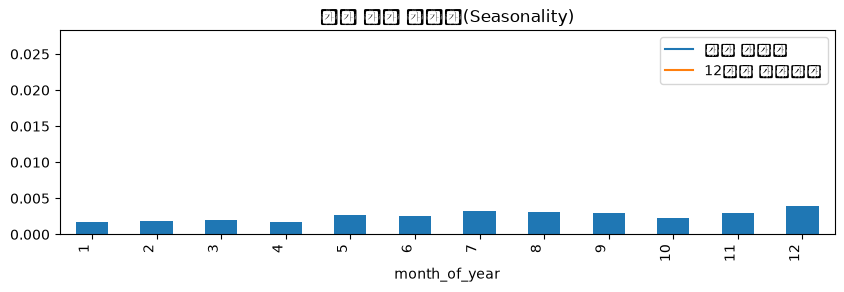

C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51092 (\N{HANGUL SYLLABLE JAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\NT751\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52264

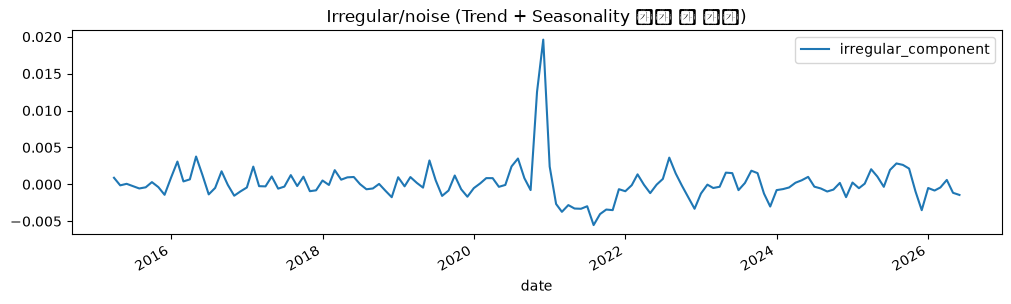

In [28]:
# judge_result 기준 시계열 성격 점검: Trend / Cyclical / Seasonality / Irregular
# 기존 df를 사용함. 날짜 컬럼 후보를 자동 탐색해서 분석.

# 1) 날짜 컬럼 후보와 타깃 코드화
date_candidates = [
	'mnfctur_de', 'mnfctur_de_or_fallback', 'inspct_de', 'rcept_de',
	'judge_de', 'date', 'dt', 'mfr_de', 'produce_de'
]

candidate = next((c for c in date_candidates if c in df.columns), None)

if candidate is None:
	# 날짜 컬럼이 없으면 'date_basis' 또는 date-like 컬럼의 이름을 보조 탐색
	date_candidates2 = [c for c in df.columns if ('date' in c.lower()) or ('de' in c.lower()) or ('dt' in c.lower())]
	candidate = date_candidates2[0] if date_candidates2 else None

if candidate is None:
	raise ValueError("날짜 컬럼을 찾을 수 없습니다. df.columns 를 확인해 주세요.")
	
# target binary
if 'judge_result' not in df.columns:
	raise ValueError("judge_result 컬럼이 없습니다.")

ts = df[[candidate, 'judge_result']].copy()
ts.columns = ['date_col', 'judge_result']
ts = ts.dropna(subset=['date_col', 'judge_result'])

# 문자열/객체 date 처리
ts['date_col'] = pd.to_datetime(ts['date_col'], errors='coerce')
ts = ts.dropna(subset=['date_col'])

ts['is_positive'] = ts['judge_result'].eq('검출').astype(int)

# 2) 월 단위 집계
monthly = (
	ts.assign(month=ts['date_col'].dt.to_period('M'))
	  .groupby('month')
	  .agg(
		  n_rows=('is_positive', 'size'),
		  검출건수=('is_positive', 'sum'),
		  불검출건수=('is_positive', lambda s: s.size - s.sum()),
		  검출률=('is_positive', 'mean'),
	  )
	  .reset_index()
	  .rename(columns={'month': 'ym'})
)

monthly['ym'] = monthly['ym'].astype(str)
monthly['date'] = pd.to_datetime(monthly['ym'])
monthly = monthly.sort_values('date').reset_index(drop=True)

# 3) Trend: 장기 추세(12개월 이동평균)
monthly['trend_12m_ma'] = monthly['검출률'].rolling(window=12, min_periods=1).mean()
monthly['trend_3m_ma'] = monthly['검출률'].rolling(window=3, min_periods=1).mean()

# 4) Seasonality: 월별 평균 검출률 (월간 패턴)
monthly['month_of_year'] = monthly['date'].dt.month
seasonality = (
	monthly.groupby('month_of_year')['검출률']
	.mean()
	.rename('월별평균검출률')
	.sort_index()
)

# 5) Cyclical: 장기 변동(12개월 이동평균에서 일반 추세를 제외한 잔차)
monthly['cyclical_component'] = monthly['검출률'] - monthly['trend_12m_ma']

# 6) Irregular: 월별 패턴 + 장기 추세를 빼고 남은 잔차
# month_of_year 평균을 seasonal baseline으로 간단히 추정
month_baseline = seasonality.reindex(monthly['month_of_year']).to_numpy()
monthly['seasonal_baseline'] = month_baseline
monthly['irregular_component'] = monthly['검출률'] - monthly['trend_12m_ma'] - (monthly['seasonal_baseline'] - seasonality.mean())

# 요약 출력
print(f"분석 날짜 컬럼: {candidate}")
print(f"총 관측 행 수: {len(ts):,}")
print(f"검출 비율 전체: {ts['is_positive'].mean() * 100:.3f}%")
print(f"분석 기간: {monthly['date'].min().date()} ~ {monthly['date'].max().date()}")

display(
	monthly[['date', 'n_rows', '검출건수', '불검출건수', '검출률', 'trend_3m_ma', 'trend_12m_ma', 'cyclical_component', 'irregular_component']]
	.tail(12)
	.round(4)
)

print("\n[Seasonality: month-of-year mean positive rate]")
display(seasonality.round(4).to_frame())

# 시각화
# 1) 검출률 + 12개월 이동평균
ax = monthly.plot(
	x='date', y=['검출률', 'trend_12m_ma'],
	kind='line', figsize=(12, 4), title='검출률(월별) / 12M 이동평균'
)
ax.legend(['월별 검출률', '12개월 이동평균'])
ax.grid(True, alpha=0.3)

# 2) 계절성(월별 평균)
seasonality.plot(
	kind='bar', figsize=(10, 3), title='월별 평균 검출률(Seasonality)'
)

# 3) 비정상/불규칙성(잔차)
monthly.plot(
	x='date', y='irregular_component', kind='line', figsize=(12, 3),
	title='Irregular/noise (Trend + Seasonality 제거 후 잔차)'
)
plt.grid(True, alpha=0.3)

# 4) 체크: 추세가 있는지 간단히 회귀 기울기
# 로그 변환 없이 검출률을 기준으로 선형 회귀
x = np.arange(len(monthly))
y = monthly['검출률'].values
slope = np.polyfit(x, y, 1)[0]

print(f"\n간단 선형 추세 기울기(월별 검출률 기준): {slope:.6f} per month")
if abs(slope) > 0.0005:
	print("→ 월별 검출률에 장기적 추세가 보입니다.")
else:
	print("→ 월별 검출률에 뚜렷한 장기 추세는 약합니다.")

# 5) 계절성 강도 체크
seasonal_strength = seasonality.std(ddof=0) / monthly['검출률'].std(ddof=0)
print(f"월별 계절성 강도(표준편차 비율): {seasonal_strength:.3f}")
if seasonal_strength > 0.5:
	print("→ 월별 반복 패턴(Seasonality)이 상대적으로 뚜렷합니다.")
else:
	print("→ 계절성은 약하거나 불명확합니다.")

# 6) 잔차의 변동성
irregular_std = monthly['irregular_component'].std(ddof=0)
print(f"잔차(불규칙성) 표준편차: {irregular_std:.4f}")

In [ ]:
mask = df['train_prdlst_nm'].eq('기타기준규격외')
count = int(mask.sum())
ratio = mask.mean() * 100

print(f"train_prdlst_nm == '기타기준규격외' 행 수: {count:,}")
print(f"전체 대비 비율: {ratio:.3f}%")

pd.DataFrame({
    '분류': ['기타기준규격외'],
    '건수': [count],
    '비율(%)': [round(ratio, 3)]
})

train_prdlst_nm == '기타기준규격외' 행 수: 291,813
전체 대비 비율: 43.133%


,분류,건수,비율(%)
0,기타기준규격외,291813,43.133


In [ ]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [ ]:
n_unique = df['train_prdlst_code'].nunique(dropna=True)
print(f"train_prdlst_code 유니크 값 수: {n_unique:,}")

train_prdlst_code 유니크 값 수: 52


In [ ]:
s = pd.to_datetime(df['mnfctur_de'], errors='coerce').dropna()
print(f"mnfctur_de 최소값: {s.min().strftime('%Y-%m-%d')}")
print(f"mnfctur_de 최대값: {s.max().strftime('%Y-%m-%d')}")

mnfctur_de 최소값: 2015-04-07
mnfctur_de 최대값: 2026-06-30


In [29]:
mask = (
    df['mnfctur_de'].notna()
    & pd.to_datetime(df['mnfctur_de'], errors='coerce').between(
        pd.Timestamp('2025-07-01'),
        pd.Timestamp('2026-06-30'),
        inclusive='both'
    )
    & df['judge_result'].eq('검출')
)

count = int(mask.sum())
print(f"2025.07.01 ~ 2026.06.30 기간 중 judge_result == '검출' 행 수: {count:,}")

2025.07.01 ~ 2026.06.30 기간 중 judge_result == '검출' 행 수: 287


In [30]:
df_컬럼요약

,컬럼명,데이터타입,결측 수,결측 비율(%),유니크 값 수,최빈값 5개,명세서_설명
0,lims_data_key,string,0,0.00,676537,"[O000001_160100103_5_4 (1), O000001_160100300_4_4 (1), O000033_170101151_1_5 (1), O000027_170101235_2_7 (1), 1471142_170100097_1_1092137 (1)]",PK. 소스별 조합 키
1,hazard_label,category,0,0.00,1,"[리스테리아 (676,537)]",위해요소명 (10종)
2,judge_result,category,0,0.00,2,"[불검출 (674,568), 검출 (1,969)]",목표변수. 검출 / 불검출. 병합 시 '하나라도 검출이면 검출'
3,src_route,category,0,0.00,2,"[domestic (628,895), overseas (47,642)]",NaN
4,data_source,category,0,0.00,1,"[식약처 (676,537)]",NaN
5,expr_iem_nm,category,0,0.00,4,"[리스테리아모노사이토제네스 (660,130), 리스테리아 모노사이토제네스 (15,798), 리스테리아 모노싸이토제네스 (605), 리스테리아 모노사이토제네스(자연치즈) (4)]",시험항목명(대표행 기준). 농관원 행은 조사 구분(anals_se)이 들어간다
6,result_value,string,0,0.00,100,"[음성 (376,777), 음성,음성,음성,음성,음성 (281,865), 불검출 (5,149), 0, 0, 0, 0, 0 (3,586), 음성, 음성, 음성, 음성, 음성 (3,335)]",검출값(원본 문자열). 정량·정성이 섞여 있어 물질 간 직접 비교 불가
7,result_value_num,float32,672760,99.44,2,"[0.0 (3,775), 2.0 (2)]",NaN
8,judge_stdr,string,669264,98.92,17,"[n=5,c=0,m=0/25g (4,692), n=5, c=0, m=0/25g (1,817), 음성 (635), 100 (62), n=5, c=0, m=0/25 g (29)]",NaN
9,judge_stdr_num,float32,676469,99.99,5,"[100.0 (62), 20.0 (3), 25.0 (1), 1000.0 (1), 0.5 (1)]",NaN


In [31]:
# train_prdlst_nm == '기타기준규격외' 인 행의 prduct_nm 값 출력
sub = df.loc[df['train_prdlst_nm'].eq('기타기준규격외'), ['prduct_nm']].copy()
sub['prduct_nm'] = sub['prduct_nm'].astype(str)

print(f"조건에 맞는 행 수: {len(sub):,}")
print(sub['prduct_nm'].tolist())

조건에 맞는 행 수: 291,813
['화이트초콜릿 65℃, 30min', '열무(세척전)', '크런치킹샌드(외포장)', '선진포크', '1703EHUD-02', '연근조림', '기타농산물(세척후)', '조미전4색야채피클-오이', '갯마을재래김(원료)', '절임갓(세척전)', '유성삼치살', '압착무', '냉동새우', '총각무-세척전', '1703CTC-08', '1704GJE-06', '신비의 작두콩 믹싱파워(볶음전)', 'Final Blend of Tuscan Lemonade /#14', 'Before Final Blend of Smirnoff Vodka Red 750 mL/#391', '깐양파(중국산)', '절임배추(세척전)', '자외선살균및건조후2(1라인)', '내가본 고춧가루(Sample test)', '기타김치:정선(무)-1차', '양파(세척전)', '완제품-도시락', '스크램블에그', '백년초쿠키(로타리오븐) 가열전', '핵산', '오징어(굽기가열후)2', '1차 사라시 탱크벽면(세척소독전)', '양파(세척후)', '마늘', '1704DSS-07', '1704DSS-10', '건쌀떡볶이', '1704EDCN-17', '1704GJU-03', '중력밀가루 2등급', '무등산빵(호랑이)-가열전', '돈족(원료)2', '후라이공정 - 내포장', '제55VYY0004호', '컨베어살균공정(6분후)-1차', '무말랭이무침(중국산)', '매운버섯칼국수건더기스프', '매운닭살꼬치 구이전', '냉동 오렌지', '유피칼시빈', '연어', '1705GYG-04', '생 연어살', '절임배추', '전통고기만두소', '마늘 처리전', '버무림후', '절단후(부재료)', '비건패티 증숙후', '건날치알(원재료)', '생오이피클슬라이스P 살균ㆍ냉각(완제품)', '생크림오믈렛빵', '절임배추(세척전)', '명태-내장제거 후(1차세척)', '키조개관자(세척전)', '케이준드레싱(외포장)-1', '우지', '영양버섯불고기도시락', '교촌 레드소스', '오이피클 탈염', '오징어